# Chapter 13 : Processing Sequences Using RNNs and CNNs

In [ ]:
import tarfile
import urllib.request
from pathlib import Path

import pandas as pd
import torch
import torchmetrics
from torch import nn
from torch.utils.data import DataLoader

In [38]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'mps'

**Exercice 1 : Use the Seq2SeqModel to forecast both rail and bus ridership for the next 14 days.**

In [39]:
def download_and_extract_ridership_data():
    data_dir = Path("datasets")
    csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
    if csv_path.is_file():                      # on teste le CSV, pas l'archive
        return csv_path
    data_dir.mkdir(parents=True, exist_ok=True)
    tarball_path = data_dir / "ridership.tgz"
    url = "https://github.com/ageron/data/raw/main/ridership.tgz"
    urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as tar:
        tar.extractall(path=data_dir, filter="data")
    return csv_path

path = download_and_extract_ridership_data()

df = pd.read_csv(path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date").drop(columns="total")
df = df[~df.index.duplicated(keep="first")]    # une seule ligne par date
df = df.asfreq("D")                            # index quotidien, aucune ligne ajoutée ici

print(df.shape, df.index.min().date(), df.index.max().date())

(7639, 3) 2001-01-01 2021-11-30


In [52]:
# Fonction d'entrainement et d'évaluation

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=10, factor=0.1):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

def fit_and_evaluate(model, train_loader, valid_loader, lr, weight_decay=0.01, n_epochs=50,
                     patience=20, factor=0.1):
    loss_fn = nn.HuberLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)
    history = train(model, optimizer, loss_fn, metric,
                    train_loader, valid_loader, n_epochs=n_epochs,
                    patience=patience, factor=factor)
    return min(history["valid_metrics"]) * 1e6

In [41]:
# Classe personnalisée pour les datasets

class Seq2SeqDataset(torch.utils.data.Dataset):
    def __init__(self, series, window_length, window_target):
        self.series = series
        self.window_length = window_length
        self.window_target = window_target

    def __len__(self):
        return len(self.series) - self.window_length - self.window_target + 1

    def __getitem__(self, idx):
        end = idx + self.window_length                       # 1er indice après la fenêtre
        window = self.series[idx:end]
        target_period = self.series[idx + 1 : end + self.window_target, :2]
        target = target_period.unfold(dimension=0, size=self.window_target, step=1)
        return window, target

In [42]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

In [43]:
mulvar_train = torch.FloatTensor(df_mulvar["2016-01":"2018-12"].values)
mulvar_valid = torch.FloatTensor(df_mulvar["2019-01":"2019-05"].values)
mulvar_test = torch.FloatTensor(df_mulvar["2019-06":].values)

In [44]:
# Création des datasets et dataloaders

window_length = 56
window_target = 14
seq_train_set = Seq2SeqDataset(mulvar_train, window_length, window_target)
seq_train_loader = DataLoader(seq_train_set, batch_size=32, shuffle=True)
seq_valid_set = Seq2SeqDataset(mulvar_valid, window_length, window_target)
seq_valid_loader = DataLoader(seq_valid_set, batch_size=32)
seq_test_set = Seq2SeqDataset(mulvar_test, window_length, window_target)
seq_test_loader = DataLoader(seq_test_set, batch_size=32)

In [45]:
import torch
import torch.nn as nn

class Seq2SeqRnnModel(nn.Module):
    def __init__(self, input_size, window_target, hidden_size=32,
                 n_layers=2, rnn_type="rnn", dropout=0.0):
        super().__init__()
        rnn_class = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[rnn_type]
        self.window_target = window_target
        self.rnn = rnn_class(
            input_size, hidden_size, num_layers=n_layers, batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.output = nn.Linear(hidden_size, window_target * 2)   # 2 variables prédites

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.output(out)
        return out.unflatten(-1, (2, self.window_target))

In [47]:
def evaluate_per_variable(model, data_loader, names=("bus", "rail"), scale=1e6,
                          last_step_only=True):
    model.eval()
    abs_err, n = None, 0
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            pred = model(X)                                  # (B, L, 2, T)
            assert pred.shape == y.shape, f"pred {tuple(pred.shape)} != y {tuple(y.shape)}"
            assert y.shape[-2] == len(names), (
                f"{y.shape[-2]} variable(s) dans les cibles, {len(names)} noms donnés")
            if last_step_only:
                pred, y = pred[:, -1], y[:, -1]              # (B, 2, T)
            err = (pred - y).abs().movedim(-2, 0).reshape(len(names), -1)   # (2, B*T)
            abs_err = err.sum(dim=1) if abs_err is None else abs_err + err.sum(dim=1)
            n += err.shape[1]
    mae = abs_err / n * scale
    return {name: mae[i].item() for i, name in enumerate(names)}

In [48]:
import math
import optuna

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            metric.update(model(X)[:, -1].contiguous(), y[:, -1].contiguous())  # dernier pas seulement
    return metric.compute()


def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=10, factor=0.1, max_grad_norm=1.0,
          trial=None, verbose=True):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": [], "lrs": []}
    best_metric, best_state = float("inf"), None

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            if not math.isfinite(loss.item()):             # divergence
                if trial is not None:
                    raise optuna.TrialPruned()
                raise RuntimeError(f"Perte non finie à l'epoch {epoch + 1} : learning rate trop élevé ?")
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred[:, -1].contiguous(), y_batch[:, -1].contiguous())

        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        if val_metric < best_metric:                       # meilleur epoch
            best_metric = val_metric
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        scheduler.step(val_metric)

        if trial is not None:                              # pruning Optuna
            trial.report(val_metric, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if verbose:
            print(f"Epoch {epoch + 1}/{n_epochs}, "
                  f"train loss: {history['train_losses'][-1]:.4f}, "
                  f"train metric: {history['train_metrics'][-1]:.4f}, "
                  f"valid metric: {val_metric:.4f}")

    model.load_state_dict(best_state)                      # le modèle final = le meilleur epoch
    return history

In [49]:
SCALE = 1e6              # seulement si la série a été divisée par 1e6 (sinon voir plus bas)
N_EPOCHS_SEARCH = 20     # fixe pour tous les essais

def build_model(rnn_type, hidden_size, n_layers, dropout):
    torch.manual_seed(42)                                  # mêmes poids de départ pour des essais comparables
    n_features = seq_train_loader.dataset.series.shape[1]
    return Seq2SeqRnnModel(
        input_size=n_features, window_target=window_target,
        hidden_size=hidden_size, n_layers=n_layers,
        rnn_type=rnn_type, dropout=dropout,
    ).to(device)


def objective(trial):
    params = {
        "rnn_type": trial.suggest_categorical("rnn_type", ["rnn", "gru", "lstm"]),
        "hidden_size": trial.suggest_int("hidden_size", 16, 128, step=16),
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3, step=0.1),   # ignoré si n_layers == 1
    }
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-1, log=True)

    model = build_model(**params)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)

    history = train(
        model, optimizer, nn.HuberLoss(), metric,
        seq_train_loader, seq_valid_loader,
        n_epochs=N_EPOCHS_SEARCH, patience=5, factor=0.5,
        trial=trial, verbose=False,
    )
    return min(history["valid_metrics"]) * SCALE           # MAE de validation, en passagers

In [50]:
from pathlib import Path
Path("models/ch13").mkdir(parents=True, exist_ok=True)

sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)

study = optuna.create_study(
    study_name="seq2seq_rnn_v3",
    direction="minimize",                                  # on minimise une erreur
    sampler=sampler,
    pruner=pruner,
    storage="sqlite:///models/ch13/optuna.db",             # sauvegarde sur disque
    load_if_exists=True,                                   # permet de reprendre
)
study.optimize(objective, n_trials=30, gc_after_trial=True)

print("Meilleure MAE de validation :", study.best_value)
print("Meilleurs paramètres :", study.best_params)

[I 2026-11-14 19:40:06,153] A new study created in RDB with name: seq2seq_rnn_v3
[I 2026-11-14 19:40:17,781] Trial 0 finished with value: 124212.3395204544 and parameters: {'rnn_type': 'gru', 'hidden_size': 80, 'n_layers': 1, 'dropout': 0.0, 'lr': 0.00013066739238053285, 'weight_decay': 0.021423021757741075}. Best is trial 0 with value: 124212.3395204544.
[I 2026-11-14 19:40:53,530] Trial 1 finished with value: 38903.314620256424 and parameters: {'rnn_type': 'gru', 'hidden_size': 128, 'n_layers': 3, 'dropout': 0.0, 'lr': 0.0002310201887845295, 'weight_decay': 8.260808399079606e-06}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:17,436] Trial 2 finished with value: 62170.155346393585 and parameters: {'rnn_type': 'gru', 'hidden_size': 48, 'n_layers': 2, 'dropout': 0.0, 'lr': 0.0003839629299804173, 'weight_decay': 6.789053271698483e-05}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:41,909] Trial 3 finished with value: 35713.52735161781 and para

Meilleure MAE de validation : 31167.974695563316
Meilleurs paramètres : {'rnn_type': 'lstm', 'hidden_size': 80, 'n_layers': 2, 'dropout': 0.1, 'lr': 0.006343056874655127, 'weight_decay': 0.011348775788931446}


In [53]:
torch.manual_seed(42)
seq_model = Seq2SeqRnnModel(input_size=5, window_target=window_target, n_layers=2, hidden_size=80, rnn_type="lstm", dropout=0.1)
seq_model = seq_model.to(device)
fit_and_evaluate(seq_model, seq_train_loader, seq_valid_loader, lr=6e-3, weight_decay=1e-2, n_epochs=65,
                 patience=8, factor=0.5)

Epoch 1/65, train loss: 0.0410, train metric: 0.2247, valid metric: 0.1536
Epoch 2/65, train loss: 0.0181, train metric: 0.1649, valid metric: 0.1494
Epoch 3/65, train loss: 0.0113, train metric: 0.1220, valid metric: 0.0983
Epoch 4/65, train loss: 0.0059, train metric: 0.0776, valid metric: 0.0708
Epoch 5/65, train loss: 0.0046, train metric: 0.0643, valid metric: 0.0600
Epoch 6/65, train loss: 0.0045, train metric: 0.0618, valid metric: 0.0535
Epoch 7/65, train loss: 0.0043, train metric: 0.0600, valid metric: 0.0497
Epoch 8/65, train loss: 0.0041, train metric: 0.0592, valid metric: 0.0497
Epoch 9/65, train loss: 0.0040, train metric: 0.0575, valid metric: 0.0682
Epoch 10/65, train loss: 0.0041, train metric: 0.0594, valid metric: 0.0484
Epoch 11/65, train loss: 0.0039, train metric: 0.0573, valid metric: 0.0448
Epoch 12/65, train loss: 0.0038, train metric: 0.0552, valid metric: 0.0581
Epoch 13/65, train loss: 0.0038, train metric: 0.0558, valid metric: 0.0452
Epoch 14/65, train lo

44835.80216765404

In [54]:
print(evaluate_per_variable(seq_model, seq_valid_loader))

{'bus': 34376.8515625, 'rail': 33921.5859375}


In [55]:
seq_model.eval()
with torch.no_grad():
    some_window = mulvar_valid[:window_length]  # shape [56, 5]
    X = some_window.unsqueeze(dim=0)            # shape [1, 56, 5]
    Y_preds = seq_model(X.to(device))    # shape [1, 56, 2, 14]
    Y_pred = Y_preds[0, -1]                     # shape [2, 14]

<class 'numpy.ndarray'> (2, 14)


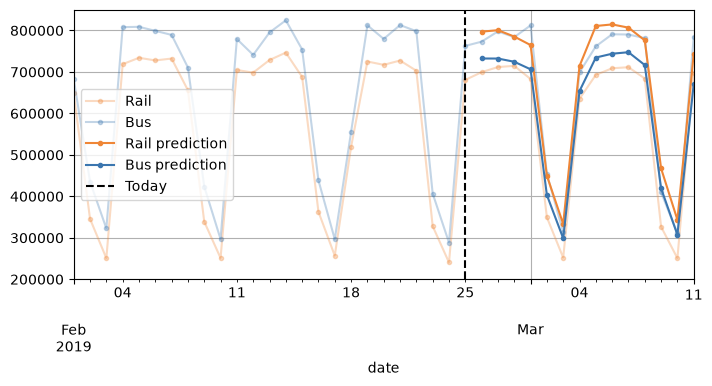

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

# Y_pred : sortie du modèle au dernier pas, forme (2, 14) = (variable, jour)
Y_pred = Y_pred.detach().cpu().numpy()
print(type(Y_pred), Y_pred.shape)           # <class 'numpy.ndarray'> (2, 14)

today = pd.Timestamp("2019-02-25")          # dernier jour de la fenêtre d'entrée
future = pd.date_range(today + pd.Timedelta(days=1), periods=Y_pred.shape[1])

# L'ordre doit être celui des deux premières colonnes du tenseur d'entrée
Y_pred_bus_s  = pd.Series(Y_pred[0] * 1e6, index=future)
Y_pred_rail_s = pd.Series(Y_pred[1] * 1e6, index=future)

recent = df[today - pd.Timedelta(days=24) : future[-1]]    # du 1er février au 11 mars

fig, ax = plt.subplots(figsize=(8, 3.5))
recent["rail"].plot(label="Rail", marker=".", ax=ax, color="#ef8636", alpha=0.3)
recent["bus"].plot(label="Bus", marker=".", ax=ax, color="#3b76af", alpha=0.3)
Y_pred_rail_s.plot(grid=True, marker=".", ax=ax, color="#ef8636", label="Rail prediction")
Y_pred_bus_s.plot(grid=True, marker=".", ax=ax, color="#3b76af", label="Bus prediction")
ax.axvline(today, color="k", linestyle="--", label="Today")
ax.set_ylim([200_000, 850_000])
ax.legend(loc="center left")
plt.show()